# **Assignment 9: K-means Clustering**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### <font color='orange'> Task - 1: Data Loading and Preprocessing (2 Marks) </font>:
1. Load the [UCI Seeds dataset](https://archive.ics.uci.edu/dataset/236/seeds).
2. Check for missing values and duplicate rows in the dataset.
3. Handle any missing or duplicate data appropriately.

Marks Distribution:

1. Loading and displaying dataset: 1 mark
2. Checking and handling missing/duplicate data: 1 mark

In [2]:
# Download and load the dataset
url = "https://archive.ics.uci.edu/static/public/236/seeds.zip"

# Define column names
column_names = [
    'area', 'perimeter', 'compactness', 'kernel_length', 'kernel_width',
    'asymmetry_coefficient', 'kernel_groove_length', 'class'
]

df = pd.read_csv(url, compression='zip', sep=r'\s+', header=None, names=column_names)

# Display dataset
print("First five rows:")
display(df.head())
print("\nDataset information:")
df.info()
print("\nDataset shape:", df.shape)

First five rows:


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coefficient,kernel_groove_length,class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   area                   210 non-null    float64
 1   perimeter              210 non-null    float64
 2   compactness            210 non-null    float64
 3   kernel_length          210 non-null    float64
 4   kernel_width           210 non-null    float64
 5   asymmetry_coefficient  210 non-null    float64
 6   kernel_groove_length   210 non-null    float64
 7   class                  210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB

Dataset shape: (210, 8)


In [3]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
area                     0
perimeter                0
compactness              0
kernel_length            0
kernel_width             0
asymmetry_coefficient    0
kernel_groove_length     0
class                    0
dtype: int64

Total missing values: 0

Number of duplicate rows: 0


**Observation:** This dataset doesn't contain any missing or duplicate values. So separate handling is not required.

In [4]:
# Extract numerical features (exclude class labels)
X = df.iloc[:, :-1].to_numpy(dtype=float)

# Standardize features
mean = np.mean(X, axis=0)
std = np.std(X, axis=0)

X_scaled = (X - mean) / std

print("Feature matrix shape:", X_scaled.shape)
print("Mean of standardized features:", np.round(X_scaled.mean(axis=0), 4))
print("Standard deviation:", np.round(X_scaled.std(axis=0), 4))

Feature matrix shape: (210, 7)
Mean of standardized features: [-0.  0.  0. -0. -0. -0. -0.]
Standard deviation: [1. 1. 1. 1. 1. 1. 1.]


### <font color='orange'> Task - 2: K-Means Clustering Implementation from Scratch (6 Marks) </font>:

1. Implement the K-Means algorithm from scratch.
2. Use K-Means++ initialization to select initial centroids.
3. Perform clustering with 3 clusters.
4. Display the final cluster centroids and the number of samples in each cluster.

Marks Distribution:

1. Correct implementation of K-Means algorithm logic: 3 marks
2. Proper use of K-Means++ initialization: 2 marks
3. Display and interpretation of results: 1 mark

In [5]:
def kmeans_plus_plus(X, k, random_state=42):
    """
    K-means++ initialization to select initial centroids
    """
    np.random.seed(random_state)

    n_samples = X.shape[0]
    centroids = []

    # Select the first centroid randomly
    first_idx = np.random.randint(n_samples)
    centroids.append(X[first_idx])

    # Select remaining centroids
    for _ in range(1, k):
        # Calculate squared distance from nearest centroid
        distances = np.min(
            np.array([np.sum((X - centroid) ** 2, axis=1) for centroid in centroids]), axis=0
        )

        # Calculate selection probabilities
        probabilities = distances / distances.sum()

        # Select next centroid
        next_idx = np.random.choice(n_samples, p=probabilities)
        centroids.append(X[next_idx])

    return np.array(centroids)

In [6]:
def kmeans(X, k, max_iter=100, tol=1e-4, random_state=42):
    """
    From-scratch implementation of K-means clustering
    """
    # Initialize centroids using K-Means++
    centroids = kmeans_plus_plus(X, k, random_state)

    for iteration in range(max_iter):
        # Calculate Euclidean distances from samples to centroids
        distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)

        # Assign each sample to its nearest centroid
        labels = np.argmin(distances, axis=1)

        # Update centroids
        new_centroids = centroids.copy()

        for cluster in range(k):
            cluster_points = X[labels == cluster]
            if len(cluster_points) > 0:
                new_centroids[cluster] = np.mean(cluster_points, axis=0)
        
        # Check convergence
        if np.linalg.norm(new_centroids - centroids) < tol:
            centroids = new_centroids
            break
        
        centroids = new_centroids

    # Perform final cluster assignment
    distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
    labels = np.argmin(distances, axis=1)

    return centroids, labels, iteration + 1

In [7]:
# Set number of clusters
k = 3

# Apply K-Means
centroids, labels, n_iterations = kmeans(X_scaled, k, max_iter=100, tol=1e-4, random_state=42)

# Convert centroids back to original feature scale
final_centroids = centroids * std + mean

# Calculate number of samples in each cluster
cluster_counts = np.bincount(labels, minlength=k)

# Display results
print("Number of iterations:", n_iterations)

print("\nFinal Cluster Centroids:")
centroid_df = pd.DataFrame(final_centroids, columns=df.columns[:-1], index=[f"Cluster {i+1}" for i in range(k)])
display(centroid_df.round(4))

print("\nNumber of samples in each cluster:")
for i in range(k):
    print(f"Cluster {i+1}: {cluster_counts[i]} samples")

print("\nTotal samples:", cluster_counts.sum())

Number of iterations: 5

Final Cluster Centroids:


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coefficient,kernel_groove_length
Cluster 1,18.4078,16.1693,0.8836,6.1678,3.6846,3.6300,6.0358
Cluster 2,11.8658,13.2565,0.8477,5.2364,2.8491,4.7772,5.1073
Cluster 3,14.3624,14.2937,0.8822,5.4948,3.2541,2.6770,5.0944



Number of samples in each cluster:
Cluster 1: 69 samples
Cluster 2: 71 samples
Cluster 3: 70 samples

Total samples: 210


**Interpretation:** The K-Means algorithm was executed with three clusters on the standardized dataset. The final centroids were converted back to the original feature scale for interpretation. The number of samples assigned to each cluster and the total number of samples were also calculated to examine the cluster distribution.

### <font color='orange'> Task - 3: Cluster Evaluation (2 Marks) </font>:

1. Evaluate the silhouette and Rand scores using scikit-learn functions.

Marks Distribution:

1. Correct computation of silhouette (1 mark) and Rand (1 mark) scores: 2 marks


In [8]:
from sklearn.metrics import silhouette_score, rand_score

# Extract actual class labels
y_true = df['class'].to_numpy()

sil_score = silhouette_score(X_scaled, labels)
r_score = rand_score(y_true, labels)

print("Silhouette Score:", round(sil_score, 4))
print("Rand Index:", round(r_score, 4))

Silhouette Score: 0.4029
Rand Index: 0.9165


### <font color='orange'> Task - 4: Ground Truth Comparison and Label Assignment (4 Marks) </font>:

1. Using the ground truth labels available in the dataset, create a table showing how many samples of each true class fall into each cluster.
2. For each cluster, assign the majority class label to that cluster.
3. Compute accuracy, precision, and recall based on this assignment.

Marks Distribution:

1. Correct tabular comparison of clusters vs. true labels: 2 mark
2. Correct label assignment and metric computation: 2 marks

In [9]:
# Create contingency table
contingency_table = pd.crosstab(y_true, labels, rownames=['Actual Class'], colnames=['Predicted Cluster'])

# Ensure all three clusters are displayed
contingency_table = contingency_table.reindex(columns=range(k), fill_value=0)

# Display comparison table
contingency_table.columns = [f"Cluster {i+1}" for i in range(k)]

print("Ground Truth vs. Predicted Clusters:")
display(contingency_table)

Ground Truth vs. Predicted Clusters:


,Cluster 1,Cluster 2,Cluster 3
Actual Class,,,
1,2,5,63
2,67,0,3
3,0,66,4


In [10]:
# Assign majority class to each cluster
majority_labels = contingency_table.idxmax(axis=0).to_dict()

# Display majority class assignments
print("Majority Class Assignment (from-scratch):")

for cluster, actual_class in majority_labels.items():
    print(f"{cluster} -> Class {actual_class}")
    
# Map cluster labels to majority class labels
y_pred = np.array([
    majority_labels[f"Cluster {label+1}"]
    for label in labels
])

# Display first 10 actual and predicted labels
print("\nFirst 10 labels")
print("Actual labels:   ", y_true[:10])
print("Predicted labels:", y_pred[:10])

Majority Class Assignment (from-scratch):
Cluster 1 -> Class 2
Cluster 2 -> Class 3
Cluster 3 -> Class 1

First 10 labels
Actual labels:    [1 1 1 1 1 1 1 1 1 1]
Predicted labels: [1 1 1 1 1 1 1 1 2 1]


In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
recall = recall_score(y_true, y_pred, average='macro', zero_division=0)

print("Evaluation metrics for from-scratch K-means clustering:")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

Evaluation metrics for from-scratch K-means clustering:
Accuracy: 0.9333
Precision: 0.9335
Recall: 0.9333


### <font color='orange'> Task - 5: Clustering using scikit-learn K-Means (3 Marks) </font>:

1. Perform clustering on the same dataset using scikit-learn’s KMeans with K-Means++ initialization and 3 clusters.
2. Compute silhouette score and Rand index.
3. Compare the results with your from-scratch implementation.

Marks Distribution:

1. Correct implementation and metric computation: 2 marks
2. Results Comparison: 1 mark

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, rand_score

# Initialize and fit scikit-learn K-Means
kmeans_sklearn = KMeans(n_clusters=3, init='k-means++', max_iter=100, tol=1e-4, random_state=42)
sklearn_labels = kmeans_sklearn.fit_predict(X_scaled)

# Compute evaluation metrics
sklearn_sil_score = silhouette_score(X_scaled, sklearn_labels)
sklearn_rand_score = rand_score(y_true, sklearn_labels)

print("Scikit-learn K-Means Results:")
print("Number of iterations:", kmeans_sklearn.n_iter_)
print("Silhouette Score:", round(sklearn_sil_score, 4))
print("Rand Index:", round(sklearn_rand_score, 4))

Scikit-learn K-Means Results:
Number of iterations: 4
Silhouette Score: 0.4024
Rand Index: 0.9103


In [13]:
# Create a comparison table
comparison = pd.DataFrame({
    'Metric': ['Silhouette Score', 'Rand Index'],
    'From-Scratch K-Means': [sil_score, r_score],
    'Scikit-learn K-Means': [sklearn_sil_score, sklearn_rand_score]
})
display(comparison.round(4))

,Metric,From-Scratch K-Means,Scikit-learn K-Means
0,Silhouette Score,0.4029,0.4024
1,Rand Index,0.9165,0.9103


**Conclusion**: Both implementations produced ***highly comparable clustering results***. The small differences may arise from implementation details, such as centroid initialization, convergence criteria, and numerical computations.

### <font color='orange'> Task - 6: Label Assignment and Evaluation for scikit-learn Clustering (3 Marks) </font>:

1. Repeat the majority class label assignment procedure for the clusters obtained from scikit-learn.
2. Compute accuracy, precision, and recall.
3. Compare these values with those from the from-scratch implementation.
4. Visualize the clusters (from-scratch and scikit-learn) using a 2D scatter plot with different colors for each cluster and mark the centroids.

Marks Distribution:

1. Correct label assignment and metric computation: 1 mark
2. Proper comparison and discussion: 1 mark
3. Visualization: 1 mark

In [14]:
# Create contingency table
sklearn_contingency_table = pd.crosstab(y_true, sklearn_labels, rownames=['Actual Class'], colnames=['Predicted Cluster'])

# Ensure all three clusters are displayed
sklearn_contingency_table = sklearn_contingency_table.reindex(columns=range(k), fill_value=0)

# Display comparison table
sklearn_contingency_table.columns = [f"Cluster {i+1}" for i in range(k)]

print("Ground Truth vs. Sklearn Predicted Clusters:")
display(sklearn_contingency_table)

Ground Truth vs. Sklearn Predicted Clusters:


,Cluster 1,Cluster 2,Cluster 3
Actual Class,,,
1,2,4,64
2,66,0,4
3,0,65,5


In [15]:
# Assign majority class to each cluster
majority_labels = sklearn_contingency_table.idxmax(axis=0).to_dict()

# Display majority class assignments
print("Majority Class Assignment (sklearn):")

for cluster, actual_class in majority_labels.items():
    print(f"{cluster} -> Class {actual_class}")
    
# Map cluster labels to majority class labels
y_pred = np.array([
    majority_labels[f"Cluster {label+1}"]
    for label in labels
])

# Display first 10 actual and predicted labels
print("\nFirst 10 labels")
print("Actual labels:   ", y_true[:10])
print("Predicted labels:", y_pred[:10])

Majority Class Assignment (sklearn):
Cluster 1 -> Class 2
Cluster 2 -> Class 3
Cluster 3 -> Class 1

First 10 labels
Actual labels:    [1 1 1 1 1 1 1 1 1 1]
Predicted labels: [1 1 1 1 1 1 1 1 2 1]


In [16]:
# Calculate evaluation metrics
sklearn_accuracy = accuracy_score(y_true, y_pred)
sklearn_precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
sklearn_recall = recall_score(y_true, y_pred, average='macro', zero_division=0)

print("Evaluation metrics for sklearn K-means clustering:")
print("Accuracy:", round(sklearn_accuracy, 4))
print("Precision:", round(sklearn_precision, 4))
print("Recall:", round(sklearn_recall, 4))

Evaluation metrics for sklearn K-means clustering:
Accuracy: 0.9333
Precision: 0.9335
Recall: 0.9333


In [17]:
# Create comparison table
classification_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall'],
    'From-Scratch K-Means': [
        accuracy, precision, recall
    ],
    'Scikit-learn K-Means': [
        sklearn_accuracy, sklearn_precision, sklearn_recall
    ]
})
display(classification_comparison.round(4))

,Metric,From-Scratch K-Means,Scikit-learn K-Means
0,Accuracy,0.9333,0.9333
1,Precision,0.9335,0.9335
2,Recall,0.9333,0.9333


**Conclusion:** Both the `from-scratch` and `scikit-learn` K-Means implementations achieved ***identical classification performance*** across all three evaluation metrics. This demonstrates that the custom implementation effectively reproduces the clustering performance of scikit-learn on the Seeds dataset.

Explained variance by two components: 88.98 %


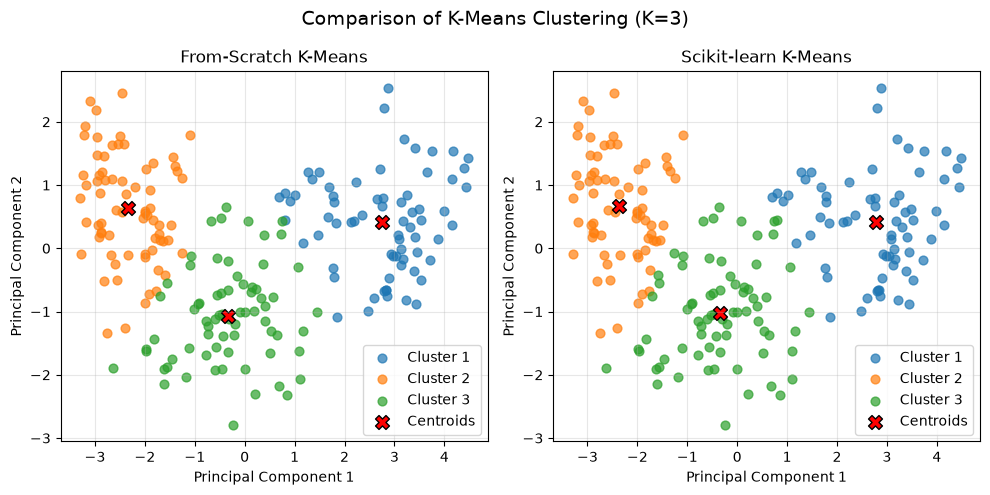

In [18]:
from sklearn.decomposition import PCA

# Apply PCA to the standardized dataset
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Transform centroids into the same 2D PCA space
scratch_centroids_pca = pca.transform(centroids)
sklearn_centroids_pca = pca.transform(kmeans_sklearn.cluster_centers_)

# Calculate explained variance
explained_variance = np.sum(pca.explained_variance_ratio_) * 100
print("Explained variance by two components:", round(explained_variance, 2), "%")

# Create side-by-side scatter plots
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
cluster_colors = ['tab:blue', 'tab:orange', 'tab:green']

# Plot from-scratch K-Means
for i in range(k):
    axes[0].scatter(
        X_pca[labels == i, 0],
        X_pca[labels == i, 1],
        color=cluster_colors[i],
        label=f'Cluster {i+1}',
        alpha=0.7,
        s=40
    )

axes[0].scatter(
    scratch_centroids_pca[:, 0],
    scratch_centroids_pca[:, 1],
    marker='X',
    s=100,
    color='red',
    edgecolors='black',
    linewidths=1,
    label='Centroids'
)

axes[0].set_title('From-Scratch K-Means')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot scikit-learn K-Means
for i in range(k):
    axes[1].scatter(
        X_pca[sklearn_labels == i, 0],
        X_pca[sklearn_labels == i, 1],
        color=cluster_colors[i],
        label=f'Cluster {i+1}',
        alpha=0.7,
        s=40
    )

axes[1].scatter(
    sklearn_centroids_pca[:, 0],
    sklearn_centroids_pca[:, 1],
    marker='X',
    s=100,
    color='red',
    edgecolors='black',
    linewidths=1,
    label='Centroids'
)

axes[1].set_title('Scikit-learn K-Means')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Comparison of K-Means Clustering (K=3)', fontsize=14)
plt.tight_layout()
plt.savefig("plots/scratch_vs_sklearn_kmeans.png")

**Observations:** The first two principal components explain most of the total variance in the dataset. Therefore, the two-dimensional PCA visualization ***retains most of the original data variability*** while reducing the feature space from seven dimensions to two. The resulting plots provide a meaningful visual comparison of the cluster distributions and centroid locations obtained from both K-Means implementations.

---
End of the assignment